Imports and Configuration

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve

sns.set_theme(style="whitegrid", palette="mako")
PRIMARY_COLOR = "#2b5c8f"
SECONDARY_COLOR = "#2a9d8f"
ACCENT_COLOR = "#e76f51"

base_dir = Path.cwd()
input_path = base_dir / 'train_and_test2.csv'
clean_path = base_dir / 'train_and_test2_clean.csv'
submission_path = base_dir / 'submission.csv'

Data Cleaning

In [3]:
df = pd.read_csv(input_path)

zero_cols = [col for col in df.columns if 'zero' in col.lower()]
df = df.drop(columns=zero_cols)

if '2urvived' in df.columns:
    df = df.rename(columns={'2urvived': 'Survived'})
elif 'survived' in df.columns:
    df = df.rename(columns={'survived': 'Survived'})

if 'PassengerId' in df.columns and 'Passengerid' not in df.columns:
    df = df.rename(columns={'PassengerId': 'Passengerid'})

df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Fare'] = df['Fare'].fillna(df['Fare'].median())


Feature Engineering

In [4]:
df['FamilySize'] = df['sibsp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
df['Sex_Pclass'] = df['Sex'].astype(str) + '_' + df['Pclass'].astype(str)

df.to_csv(clean_path, index=False)

EDA and Data Partitioning

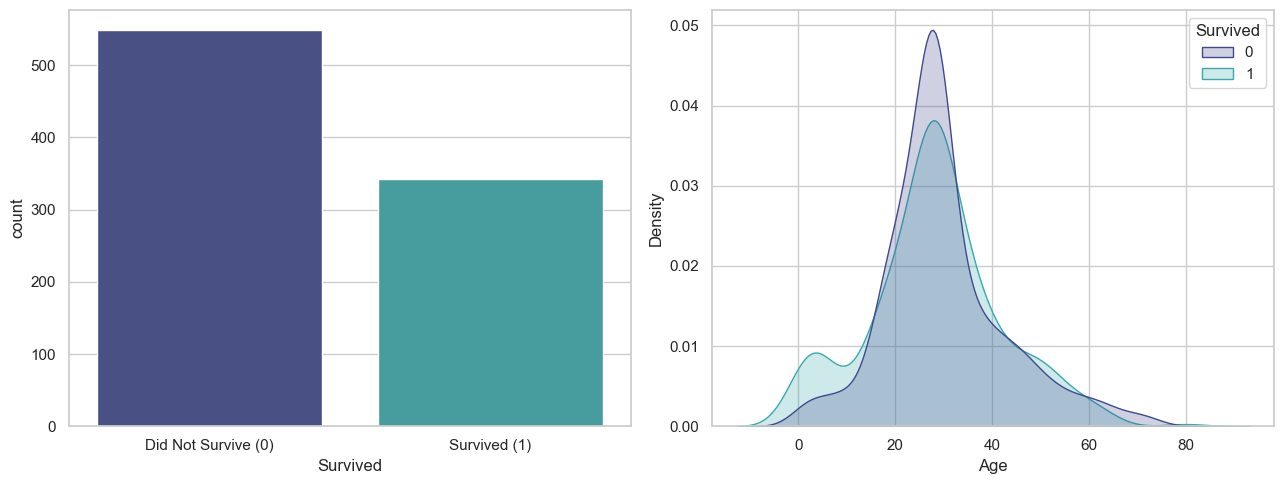

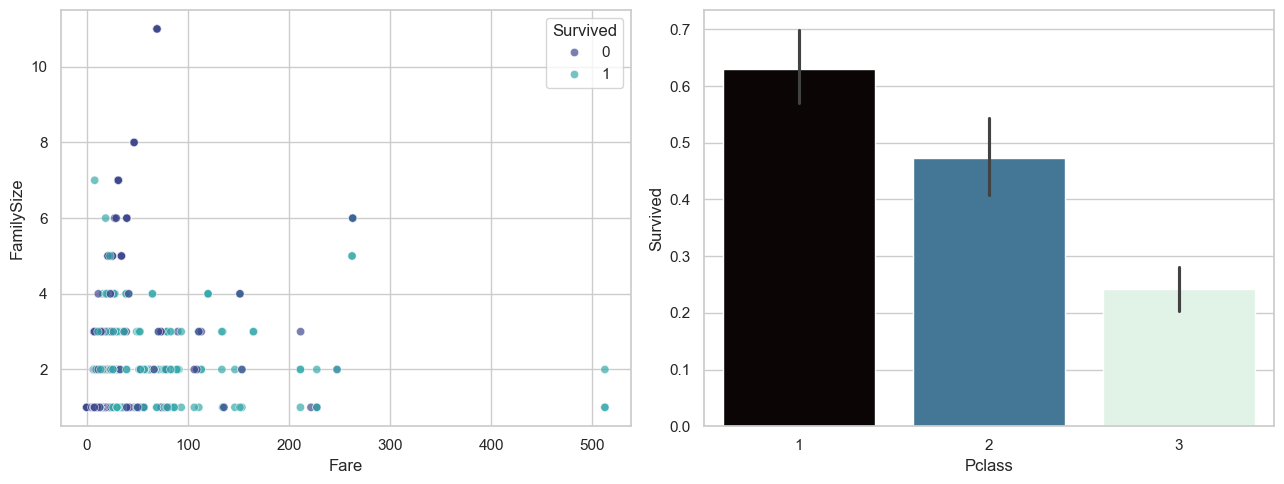

In [5]:
train_df = df[df['Passengerid'] <= 891].copy()
test_df = df[df['Passengerid'] >= 892].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=train_df, x='Survived', hue='Survived', palette="mako", legend=False, ax=axes[0])
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Did Not Survive (0)", "Survived (1)"])

sns.kdeplot(data=train_df, x='Age', hue='Survived', fill=True, common_norm=False, palette="mako", ax=axes[1])
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=train_df, x='Fare', y='FamilySize', hue='Survived', palette="mako", alpha=0.7, ax=axes[0])
sns.barplot(data=train_df, x='Pclass', y='Survived', hue='Pclass', palette="mako", legend=False, ax=axes[1])
plt.tight_layout()
plt.show()


Pipeline Construction

In [6]:
X = train_df.drop(columns=['Survived', 'Passengerid'])
y = train_df['Survived'].astype(int)

numeric_features = ['Age', 'Fare', 'sibsp', 'Parch', 'Pclass', 'FamilySize', 'IsAlone']
categorical_features = ['Sex', 'Embarked', 'Sex_Pclass']

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median'))]), numeric_features),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
        ]), categorical_features)
    ]
)

model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(n_estimators=800, max_depth=5, min_samples_split=4, 
                                     min_samples_leaf=2, max_features='sqrt', random_state=42, n_jobs=-1))
])


Model Training & Validation

Validation Accuracy: 0.8045
Validation ROC-AUC: 0.8441


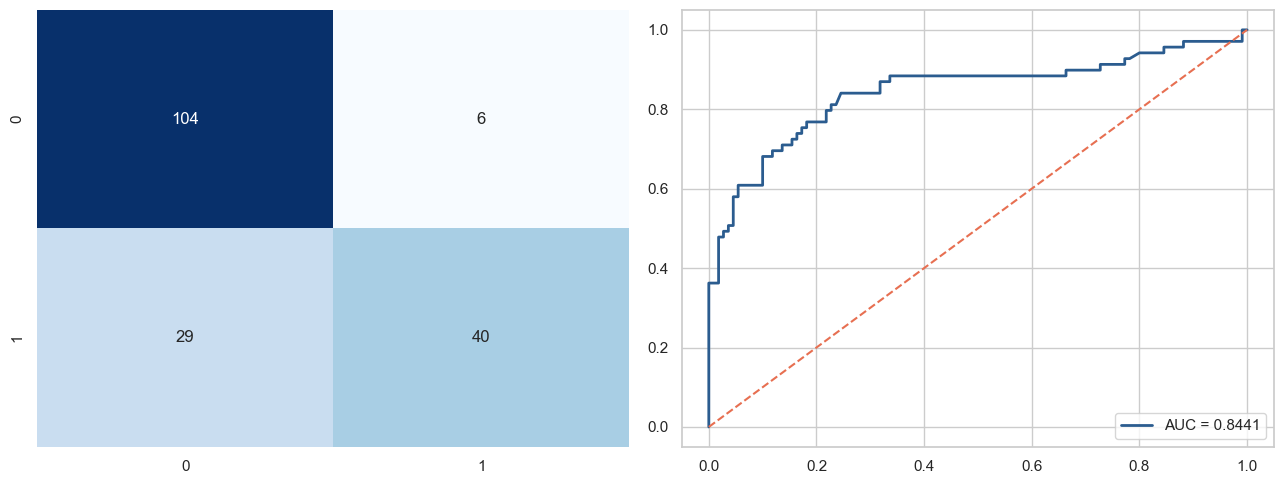

In [7]:
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model_pipeline.fit(X_train, y_train)

y_pred = model_pipeline.predict(X_valid)
y_prob = model_pipeline.predict_proba(X_valid)[:, 1]

print('Validation Accuracy:', round(accuracy_score(y_valid, y_pred), 4))
print('Validation ROC-AUC:', round(roc_auc_score(y_valid, y_prob), 4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(confusion_matrix(y_valid, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0])
fpr, tpr, _ = roc_curve(y_valid, y_prob)
axes[1].plot(fpr, tpr, color=PRIMARY_COLOR, lw=2, label=f"AUC = {roc_auc_score(y_valid, y_prob):.4f}")
axes[1].plot([0, 1], [0, 1], color=ACCENT_COLOR, linestyle="--")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()


Feature Importance

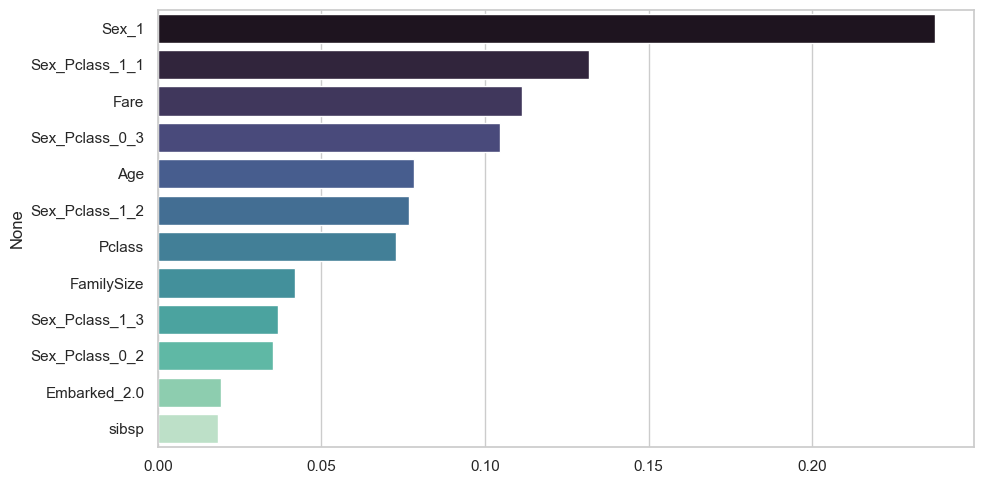

In [8]:
ohe_cols = model_pipeline.named_steps['preprocessor'].named_transformers_['categorical'].named_steps['onehot'].get_feature_names_out(categorical_features)
all_feature_names = numeric_features + list(ohe_cols)
importances = model_pipeline.named_steps['model'].feature_importances_
feat_imp = pd.Series(importances, index=all_feature_names).sort_values(ascending=False).head(12)

plt.figure(figsize=(10, 5))
sns.barplot(x=feat_imp.values, y=feat_imp.index, hue=feat_imp.index, palette="mako", legend=False)
plt.tight_layout()
plt.show()


Final Submission Generation

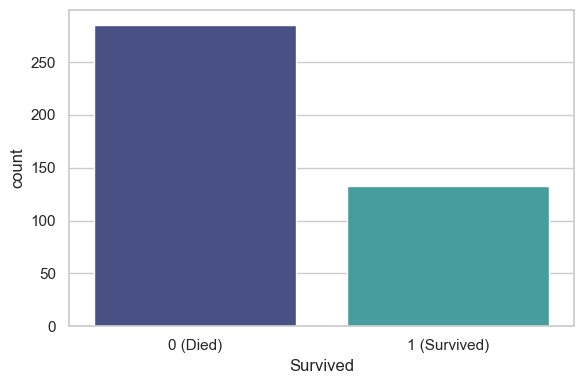

In [9]:
X_full = train_df.drop(columns=['Survived', 'Passengerid'])
y_full = train_df['Survived'].astype(int)
X_test = test_df.drop(columns=['Survived', 'Passengerid'])

model_pipeline.fit(X_full, y_full)
predictions = model_pipeline.predict(X_test)

submission = pd.DataFrame({'PassengerId': test_df['Passengerid'].astype(int), 'Survived': predictions.astype(int)})
submission = submission.sort_values(by='PassengerId').reset_index(drop=True)
submission.to_csv(submission_path, index=False)

plt.figure(figsize=(6, 4))
sns.countplot(data=submission, x='Survived', hue='Survived', palette="mako", legend=False)
plt.xticks([0, 1], ["0 (Died)", "1 (Survived)"])
plt.tight_layout()
plt.show()
